OMG-Emotion ResNet-50 Valence-Arousal

In [1]:
from google.colab import drive
drive.mount("/content/drive")

!pip install -q -U "yt-dlp[default]"
!curl -fsSL https://deno.land/install.sh | sh > /dev/null 2>&1
!pip install -q facenet-pytorch --no-deps
from facenet_pytorch import MTCNN
import os
import glob
import time
import subprocess
from collections import Counter, defaultdict, deque
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models

os.environ["PATH"] += ":/root/.deno/bin"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
DRIVE_WORK_DIR = "/content/drive/MyDrive/omg_emotion_shutter"
FRAMES_DIR = os.path.join(DRIVE_WORK_DIR, "omg_face_frames")
RAW_VID_DIR = "/content/omg_raw_videos"
os.makedirs(FRAMES_DIR, exist_ok=True)
os.makedirs(RAW_VID_DIR, exist_ok=True)
#currently CLONING THE REPO. but, the csv files required are also attached in the code base as the files. since in colab, it was easier to clone than upload to drive, but when testing, can just use those files!
REPO_DIR = "/content/OMGEmotionChallenge"
if not os.path.exists(REPO_DIR):
    !git clone -q https://github.com/knowledgetechnologyuhh/OMGEmotionChallenge.git /content/OMGEmotionChallenge
train_df = pd.read_csv(os.path.join(REPO_DIR, "omg_TrainVideos.csv"))
val_df = pd.read_csv(os.path.join(REPO_DIR, "omg_ValidationVideos.csv"))
print("OMG-Emotion splits exists")
print(train_df[["video", "utterance", "start", "end", "valence", "arousal"]].head(3))

Mounted at /content/drive
Using device: cuda
Loaded OMG-Emotion splits -> Train utterances: 2442 | Val utterances: 617
       video        utterance      start        end   valence   arousal
0  5b44393ed  utterance_4.mp4  15.412684  19.682865 -0.023697  0.170091
1  5b44393ed  utterance_6.mp4  21.250822  36.796949  0.292947  0.417668
2  5b44393ed  utterance_7.mp4  37.130556  45.337310  0.325004  0.398646


Add cookies from youtube account (important or videos will NOT download), then download videos from dataset listed

In [9]:
COOKIES_PATH = os.path.join(DRIVE_WORK_DIR, "cookies.txt")
print("cookies from:", COOKIES_PATH)
#open source for preocessing where face is
mtcnn = MTCNN(keep_all=False, device=device)
def extract_largest_face(frame_rgb):
    boxes, _ = mtcnn.detect(frame_rgb)
    if boxes is None or len(boxes) == 0:
        return None
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    x1, y1, x2, y2 = boxes[int(np.argmax(areas))]
    w, h = x2 - x1, y2 - y1
    pad_x, pad_y = 0.12 * w, 0.15 * h
    x1 = max(0, int(x1 - pad_x))
    y1 = max(0, int(y1 - pad_y))
    x2 = min(frame_rgb.shape[1], int(x2 + pad_x))
    y2 = min(frame_rgb.shape[0], int(y2 + pad_y))
    if x2 <= x1 + 20 or y2 <= y1 + 20:
        return None
    return Image.fromarray(frame_rgb[y1:y2, x1:x2]).resize((224, 224), Image.BILINEAR)

def download_and_extract_split(df, split_name, frames_per_utterance=4):
    split_dir = os.path.join(FRAMES_DIR, split_name)
    os.makedirs(split_dir, exist_ok=True)

    grouped = list(df.groupby(["link", "video"]))
    downloaded_vids = 0
    first_error = None
#since its audio and visual, separated by utterances, group by full video to download then split by utterance
    for idx, ((link, vid_id), group) in enumerate(tqdm(grouped, desc=f"Processing {split_name} videos")):
        vid_id = str(vid_id).strip()
        url = str(link).strip()
        already_done = True
        for _, row in group.iterrows():
            utt_uid = f"{vid_id}_{str(row['utterance']).replace('.mp4', '').strip()}"
            if not os.path.exists(os.path.join(split_dir, f"{utt_uid}_f0.jpg")):
                already_done = False
                break
        if already_done: #dont redownload
            downloaded_vids += 1
            continue
        out_path = os.path.join(RAW_VID_DIR, f"{vid_id}.mp4")
        for part_file in glob.glob(os.path.join(RAW_VID_DIR, f"{vid_id}.mp4*")):
            os.remove(part_file)
            #troubleshoot cookies and youtube video access issues
        cmd = ["yt-dlp", "--no-warnings", "--ignore-errors","--socket-timeout", "15", "--retries", "2","--extractor-args", "youtube:player_client=web,default","--cookies", COOKIES_PATH,"--sleep-requests", "1.0","-f", "best[height<=480][ext=mp4]/best[ext=mp4]/best","-o", out_path, url]

        try:
            res = subprocess.run(cmd, capture_output=True, text=True, timeout=45)
            if not os.path.exists(out_path) and first_error is None:
                first_error = res.stderr.strip()[:400]
        except subprocess.TimeoutExpired:
            for part_file in glob.glob(os.path.join(RAW_VID_DIR, f"{vid_id}.mp4*")):
                os.remove(part_file)
            continue
        if not os.path.exists(out_path) or os.path.getsize(out_path) <= 10_000:
            continue
        downloaded_vids += 1
        cap = cv2.VideoCapture(out_path)
        fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
        for _, row in group.iterrows():
            start_sec, end_sec = float(row["start"]), float(row["end"])
            if end_sec <= start_sec + 0.1:
                continue
            utt_uid = f"{vid_id}_{str(row['utterance']).replace('.mp4', '').strip()}"
            margin = 0.1 * (end_sec - start_sec)
            timestamps = np.linspace(start_sec + margin, end_sec - margin, num=frames_per_utterance)
            for f_i, t_sec in enumerate(timestamps):
                frame_path = os.path.join(split_dir, f"{utt_uid}_f{f_i}.jpg")
                if os.path.exists(frame_path):
                    continue
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(t_sec * fps))
                ret, frame_bgr = cap.read()
                if not ret or frame_bgr is None:
                    continue
                face_img = extract_largest_face(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
                if face_img is not None:
                    face_img.save(frame_path, quality=92)
        cap.release()
        os.remove(out_path)

    total_imgs = len(glob.glob(os.path.join(split_dir, "*.jpg")))
    print(f"videos processed for {split_name} num: {downloaded_vids}/{len(grouped)}")
    if total_imgs == 0 and first_error:
        print(f"[{split_name}] YouTube download error:\n{first_error}")
#IF you run into extra errors with downloading the videos, run just train with one cookie txt file, import a new file for just val
download_and_extract_split(train_df, "train", frames_per_utterance=4)
download_and_extract_split(val_df, "val", frames_per_utterance=3)

Using YouTube cookies from: /content/drive/MyDrive/omg_emotion_shutter/cookies.txt


Processing val videos: 100%|██████████| 60/60 [13:35<00:00, 13.59s/it]

[val] Videos processed: 33/60 | Saved face frames on Drive: 992


Load up and balance both the training and validation sets

In [10]:
#the dataset does not split into different physical categories, but we can infer them as the valence scores and arousal scores themselves are used TO find the type of emotional category
def va_to_bucket(v, a):
    if abs(v) <= 0.25 and abs(a) <= 0.25:
        return "Neutral"
    if v >= 0.0 and a > 0.55:
        return "Surprise"
    if v > 0.0:
        return "Happy"
    if a > 0.20:
        return "Angry/Fear"
    return "Sad"

def build_omg_va_records(df, split_name):
    split_dir = os.path.join(FRAMES_DIR, split_name)
    records = []
    for _, row in df.iterrows():
        vid_id = str(row["video"]).strip()
        val, aro = float(row["valence"]), float(row["arousal"])
        if np.isnan(val) or np.isnan(aro):
            continue
        v_norm = float(np.clip(val, -1.0, 1.0))
        a_norm = float(np.clip(2.0 * aro - 1.0, -1.0, 1.0))
        utt_uid = f"{vid_id}_{str(row['utterance']).replace('.mp4', '').strip()}"
        bucket = va_to_bucket(v_norm, a_norm)
        for fp in sorted(glob.glob(os.path.join(split_dir, f"{utt_uid}_f*.jpg"))):
            records.append({"path": fp,"valence": v_norm, "arousal": a_norm,"utterance_uid": utt_uid,"bucket": bucket})
    print(f"{len(records)}  frames loadedfor {split_name.upper()} ")
    return records

train_records = build_omg_va_records(train_df, "train")
val_records = build_omg_va_records(val_df, "val")
assert len(train_records) > 0 and len(val_records) > 0, "ERRORS WITH EXTRACTED FRAMES"
train_transform = transforms.Compose([transforms.Resize((236, 236)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12))
])

val_transform = transforms.Compose([transforms.Resize((224, 224)),transforms.ToTensor(),transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])

BUCKET_WEIGHTS = {"Neutral": 0.60,"Happy": 0.75,"Surprise": 1.60,"Angry/Fear": 2.60,"Sad": 2.40,}
class OMGWeightedVADataset(Dataset):
    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform
    def __len__(self):
        return len(self.records)
    def __getitem__(self, idx):
        rec = self.records[idx]
        with Image.open(rec["path"]) as img:
            image = img.convert("RGB")
        if self.transform:
            image = self.transform(image)
        target_va = torch.tensor([rec["valence"], rec["arousal"]], dtype=torch.float32)
        weight = torch.tensor(BUCKET_WEIGHTS.get(rec["bucket"], 1.0), dtype=torch.float32)
        return image, target_va, weight, rec["utterance_uid"]

# BALANCING WEIGHTS!!!!
neg_mask = np.array([r["valence"] < -0.10 for r in train_records])
n_neg = int(neg_mask.sum())
n_pos = len(train_records) - n_neg
sample_probs = np.where(neg_mask, 0.5/ max(n_neg, 1), 0.5 / max(n_pos, 1))
sampler = WeightedRandomSampler(weights=torch.from_numpy(sample_probs).double(), num_samples=len(train_records), replacement=True)
train_loader = DataLoader(OMGWeightedVADataset(train_records, train_transform), batch_size=64, sampler=sampler, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(OMGWeightedVADataset(val_records, val_transform), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
print(f"Balanced DataLoaders where there are {n_neg} Neg frames & {n_pos} Non-neg frames")

TRAIN frames loaded: 2240 | Breakdown: {'Happy': 1212, 'Surprise': 171, 'Sad': 420, 'Neutral': 373, 'Angry/Fear': 64}
VAL frames loaded: 992 | Breakdown: {'Happy': 547, 'Neutral': 220, 'Sad': 111, 'Surprise': 63, 'Angry/Fear': 51}
Balanced DataLoaders where there are Neg frames: 496 | Non-neg frames: 1744


Fit and train model, save best checkpoint for the params

In [11]:
class ResNet50OMGVisualVA(nn.Module):
    def __init__(self, dropout=0.45):
        super().__init__()
        self.backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.va_head = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(in_features, 256),
            nn.GELU(),
            nn.Dropout(p=dropout * 0.7),
            nn.Linear(256, 2),
            nn.Tanh())
    def forward(self, x):
        return self.va_head(self.backbone(x))

def compute_ccc(y_true, y_pred):
    y_true, y_pred = y_true.float(), y_pred.float()
    mean_t, mean_p = torch.mean(y_true), torch.mean(y_pred)
    var_t = torch.var(y_true, unbiased=False)
    var_p = torch.var(y_pred, unbiased=False)
    cov = torch.mean((y_true - mean_t) * (y_pred - mean_p))
    return (2.0 * cov)/(var_t + var_p + (mean_t- mean_p) ** 2 + 1e-8)
@torch.no_grad()
def evaluate_omg_va(model, loader, device):
    model.eval()
    utt_preds = defaultdict(list)
    utt_targets = {}
    for images, targets, _, utt_uids in loader:
        preds = model(images.to(device, non_blocking=True)).cpu().numpy()
        targs = targets.numpy()
        for p, t, uid in zip(preds, targs, utt_uids):
            utt_preds[uid].append(p)
            utt_targets[uid] = t

    u_pred = torch.tensor([np.mean(utt_preds[uid], axis=0) for uid in utt_targets], dtype=torch.float32)
    u_true = torch.tensor([utt_targets[uid] for uid in utt_targets], dtype=torch.float32)
    val_ccc = compute_ccc(u_true[:, 0], u_pred[:, 0]).item()
    aro_ccc = compute_ccc(u_true[:, 1], u_pred[:, 1]).item()
    val_sagr = torch.mean(((u_true[:, 0] >= 0) == (u_pred[:, 0] >= 0)).float()).item()
    aro_sagr = torch.mean(((u_true[:, 1] >= 0) == (u_pred[:, 1] >= 0)).float()).item()
    return {"val_ccc": val_ccc,"aro_ccc": aro_ccc, "mean_ccc": 0.5 * (val_ccc + aro_ccc), "val_sagr": val_sagr, "aro_sagr": aro_sagr,}

SAVE_PATH = os.path.join(DRIVE_WORK_DIR, "resnet50_omg_visual_va_polarity_balanced.pth")
TOTAL_EPOCHS = 14
model = ResNet50OMGVisualVA(dropout=0.45).to(device)
smooth_l1_none = nn.SmoothL1Loss(beta=0.15, reduction="none")

# to reduce overfitting, i freeze the model backbone in the beginning epochs
for p in model.backbone.parameters():
    p.requires_grad = False
optimizer = torch.optim.AdamW(model.va_head.parameters(), lr=1e-3, weight_decay=1e-2)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())
best_mean_ccc = -1.0
for epoch in range(1, TOTAL_EPOCHS + 1):
    if epoch == 4:#unfreeze
        for p in model.backbone.layer4.parameters():
            p.requires_grad = True
        optimizer = torch.optim.AdamW([
            {"params": model.backbone.layer4.parameters(), "lr": 5e-5},
            {"params": model.va_head.parameters(), "lr": 3e-4}
        ], weight_decay=1e-2)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TOTAL_EPOCHS - 3, eta_min=1e-6)
    elif epoch == 9: #unfreeze
        for p in model.backbone.layer3.parameters():
            p.requires_grad = True
        optimizer = torch.optim.AdamW([{"params": model.backbone.layer3.parameters(), "lr": 2e-5},{"params": model.backbone.layer4.parameters(), "lr": 3e-5},{"params": model.va_head.parameters(), "lr": 1.5e-4}], weight_decay=1e-2)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TOTAL_EPOCHS - 8, eta_min=1e-6)
    model.train()
    running_loss, total_samples = 0.0, 0
    for images, targets, weights, _ in train_loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        weights = weights.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            preds = model(images)
        w_l1_v = (smooth_l1_none(preds[:, 0].float(), targets[:, 0]) * weights).mean()
        w_l1_a = (smooth_l1_none(preds[:, 1].float(), targets[:, 1]) * weights).mean()
        loss_v = (1.0 - compute_ccc(targets[:, 0], preds[:, 0])) + w_l1_v
        loss_a = (1.0 - compute_ccc(targets[:, 1], preds[:, 1])) + w_l1_a
        loss = 0.5 * (loss_v + loss_a)
        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

    if epoch >= 4:
        scheduler.step()
    m = evaluate_omg_va(model, val_loader, device)
    print(f"For epoh {epoch:02d}/{TOTAL_EPOCHS:02d}, Loss: {running_loss/total_samples:.4f}, Val CCC: {m['val_ccc']:.3f} (Sign {m['val_sagr']*100:.1f}%), Aro CCC: {m['aro_ccc']:.3f} (Sign {m['aro_sagr']*100:.1f}%)")
    if m["mean_ccc"] > best_mean_ccc:
        best_mean_ccc = m["mean_ccc"]
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"current best mean CCC: {best_mean_ccc:.4f})")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 187MB/s]
/tmp/ipykernel_998/4187591298.py:37: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  u_pred = torch.tensor([np.mean(utt_preds[uid], axis=0) for uid in utt_targets], dtype=torch.float32)


For epoh 01/14, Loss: 1.0575, Val CCC: 0.016 (Sign 70.2%), Aro CCC: -0.012 (Sign 44.0%)
current best mean CCC: 0.0021)
For epoh 02/14, Loss: 0.8441, Val CCC: 0.117 (Sign 69.0%), Aro CCC: 0.069 (Sign 48.8%)
current best mean CCC: 0.0933)
For epoh 03/14, Loss: 0.7706, Val CCC: 0.083 (Sign 70.8%), Aro CCC: 0.083 (Sign 47.0%)
For epoh 04/14, Loss: 0.7258, Val CCC: 0.095 (Sign 67.3%), Aro CCC: 0.078 (Sign 49.1%)
For epoh 05/14, Loss: 0.6937, Val CCC: 0.130 (Sign 72.9%), Aro CCC: 0.096 (Sign 48.8%)
current best mean CCC: 0.1128)
For epoh 06/14, Loss: 0.6898, Val CCC: 0.120 (Sign 72.3%), Aro CCC: 0.095 (Sign 48.8%)
For epoh 07/14, Loss: 0.6499, Val CCC: 0.132 (Sign 71.1%), Aro CCC: 0.107 (Sign 51.8%)
current best mean CCC: 0.1192)
For epoh 08/14, Loss: 0.6133, Val CCC: 0.131 (Sign 71.1%), Aro CCC: 0.118 (Sign 51.8%)
current best mean CCC: 0.1244)
For epoh 09/14, Loss: 0.6062, Val CCC: 0.136 (Sign 73.2%), Aro CCC: 0.120 (Sign 50.6%)
current best mean CCC: 0.1283)
For epoh 10/14, Loss: 0.5844, 

Evaluations

In [17]:
best_ckpt_path = os.path.join(DRIVE_WORK_DIR, "resnet50_omg_visual_va_polarity_balanced.pth")
model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
model.eval()
uid_to_bucket = {r["utterance_uid"]: r["bucket"] for r in val_records}
utt_preds = defaultdict(list)
utt_targets = {}

with torch.no_grad():
    for imgs, targets, weights, uids in val_loader:
        preds = model(imgs.to(device)).cpu().numpy()
        targs = targets.numpy()
        for p, t, uid in zip(preds, targs, uids):
            utt_preds[uid].append(p)
            utt_targets[uid] = t
uids = list(utt_targets.keys())
y_pred = np.array([np.mean(utt_preds[u], axis=0) for u in uids])
y_true = np.array([utt_targets[u] for u in uids])
buckets = np.array([uid_to_bucket.get(u, "Unknown") for u in uids])

def np_ccc(x, y):
    vx, vy = np.var(x), np.var(y)
    cov = np.mean((x - np.mean(x)) * (y - np.mean(y)))
    return (2 * cov) / (vx + vy + (np.mean(x) - np.mean(y)) ** 2 + 1e-8)
val_ccc = np_ccc(y_pred[:, 0], y_true[:, 0])
aro_ccc = np_ccc(y_pred[:, 1], y_true[:, 1])
mean_ccc = (val_ccc + aro_ccc) / 2
val_sign_accuracy = np.mean((y_pred[:, 0] >= 0) == (y_true[:, 0] >= 0))
aro_sign_accuracy = np.mean((y_pred[:, 1] >= 0) == (y_true[:, 1] >= 0))

print(f"Test Mean CCC: {mean_ccc:.4f}, Test Valence CCC: {val_ccc:.4f}, Test Arousal CCC: {aro_ccc:.4f}, Test Valence Sign Accuracy: {val_sign_accuracy:.4f}, Test Arousal Sign Accuracy: {aro_sign_accuracy:.4f}")
# accuracy per emotion class for test
print("Accuracy per emotion class:")
for b_name in ["Neutral", "Happy", "Surprise", "Angry/Fear", "Sad"]:
    mask = (buckets == b_name)
    class_acc = np.mean((y_pred[mask, 0] >= 0) == (y_true[mask, 0] >= 0)) if mask.sum() > 0 else 0
    print(f"Accuracy for emotion class {b_name.upper()}: {class_acc:.4f}")

Test Mean CCC: 0.1360, Test Valence CCC: 0.1450, Test Arousal CCC: 0.1271, Test Valence Sign Accuracy: 0.7530, Test Arousal Sign Accuracy: 0.5060
Accuracy per emotion class:
Accuracy for emotion class NEUTRAL: 0.6486
Accuracy for emotion class HAPPY: 0.8817
Accuracy for emotion class SURPRISE: 0.9524
Accuracy for emotion class ANGRY/FEAR: 0.1176
Accuracy for emotion class SAD: 0.5000


We plot the following here: Predicted vs. Ground-Truth Valence, Predicted vs. Ground-Truth Arousal, and Ground Truth vs. Predicted Valence Distribution.


/tmp/ipykernel_998/549557297.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
/tmp/ipykernel_998/549557297.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()


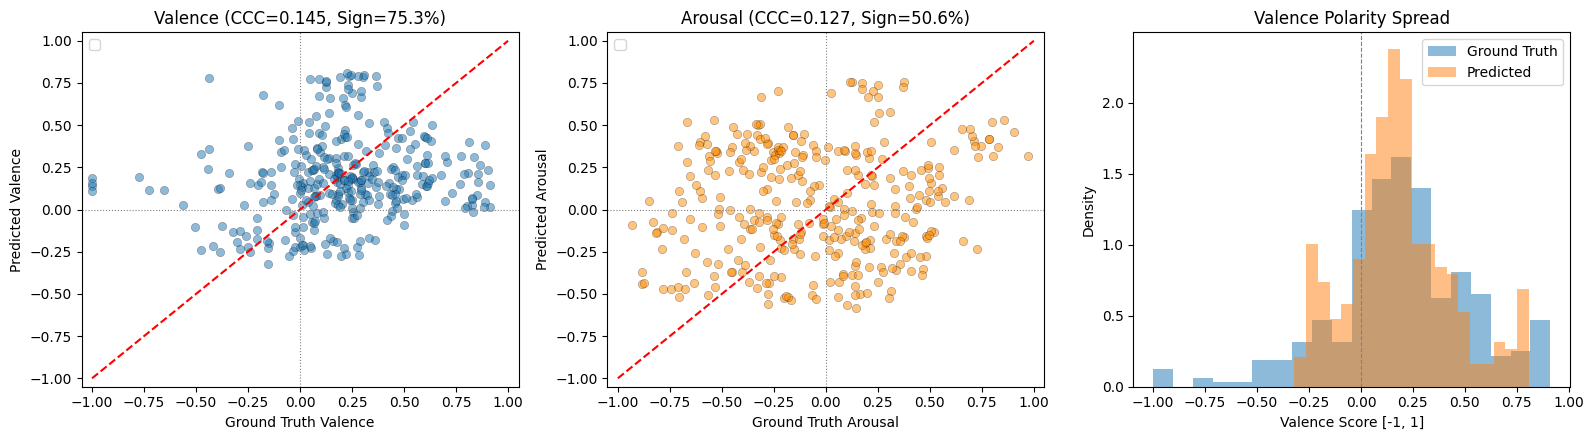

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(y_true[:, 0], y_pred[:, 0], alpha=0.5, edgecolors="k", linewidth=0.3)
axes[0].plot([-1, 1], [-1, 1], "r--")
axes[0].axhline(0, color="gray", linestyle=":", linewidth=0.8)
axes[0].axvline(0, color="gray", linestyle=":", linewidth=0.8)
axes[0].set_xlim(-1.05, 1.05)
axes[0].set_ylim(-1.05, 1.05)
axes[0].set_xlabel("Ground Truth Valence")
axes[0].set_ylabel("Predicted Valence")
axes[0].set_title(f"Valence (CCC={val_ccc:.3f}, Sign={val_sign_accuracy*100:.1f}%)")
axes[0].legend()

axes[1].scatter(y_true[:, 1], y_pred[:, 1], alpha=0.5, color="darkorange", edgecolors="k", linewidth=0.3)
axes[1].plot([-1, 1], [-1, 1], "r--")
axes[1].axhline(0, color="gray", linestyle=":", linewidth=0.8)
axes[1].axvline(0, color="gray", linestyle=":", linewidth=0.8)
axes[1].set_xlim(-1.05, 1.05)
axes[1].set_ylim(-1.05, 1.05)
axes[1].set_xlabel("Ground Truth Arousal")
axes[1].set_ylabel("Predicted Arousal")
axes[1].set_title(f"Arousal (CCC={aro_ccc:.3f}, Sign={aro_sign_accuracy*100:.1f}%)")
axes[1].legend()

axes[2].hist(y_true[:, 0], bins=20, alpha=0.5, label="Ground Truth", density=True)
axes[2].hist(y_pred[:, 0], bins=20, alpha=0.5, label="Predicted", density=True)
axes[2].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[2].set_xlabel("Valence Score [-1, 1]")
axes[2].set_ylabel("Density")
axes[2].set_title("Valence Polarity Spread")
axes[2].legend()

plt.tight_layout()
plt.show()